# INF201 - Deliverable 1
**Gruppe / Navn:** [Amalie Berntsen, Sander Vikse]  
**GitHub Repository:** https://github.com/amaliebern-code/INF201-deliverable-1.git

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import yaml

client_id = 'DIN_CLIENT_ID_HER'

print("Client ID er definert og klar!")


Client ID er definert og klar!


## Task 1: Temperature
Henter daglig gjennomsnittstemperatur for Ås i 2025, beregner oppsummeringsstatistikk og plotter temperaturforløpet.


Data hentet fra frost.met.no!

--- Oppsummeringstabell for temperatur i Ås (2025) ---
    Mean  Median   Min  Max
7.903571    8.35 -16.1 24.5


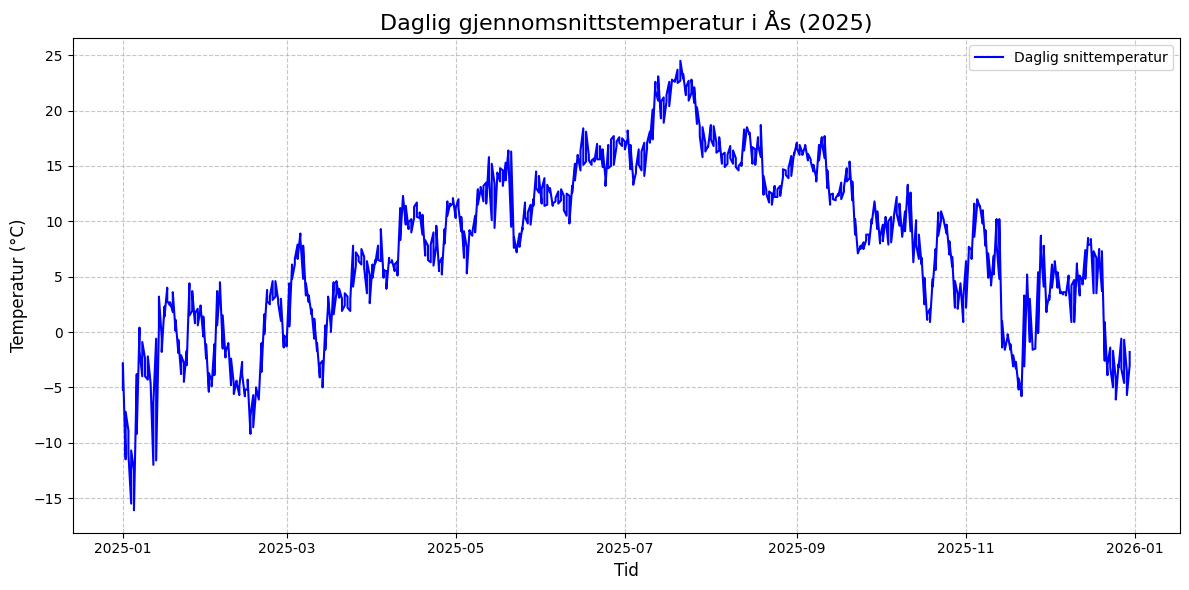

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

client_id = 'DIN_CLIENT_ID_HER'

# Definer endpoint og parametere for 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Sender forespørselen
r = requests.get(endpoint, parameters, auth=(client_id, ''))
json = r.json()

if r.status_code == 200:
    data = json['data']
    print('Data hentet fra frost.met.no!')
    
    # Legger dataene inn i en Pandas DataFrame
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        for obs in item['observations']:
            rows.append({
                'referenceTime': ref_time,
                'value': obs['value']
            })
    
    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])
    
    # Skriver ut oppsummeringstabell først
    summary_data = {
        'Mean': [df['value'].mean()],
        'Median': [df['value'].median()],
        'Min': [df['value'].min()],
        'Max': [df['value'].max()]
    }
    
    summary_table = pd.DataFrame(summary_data)
    print("\n--- Oppsummeringstabell for temperatur i Ås (2025) ---")
    print(summary_table.to_string(index=False))

    # Viser plottet til slutt
    plt.figure(figsize=(12, 6))
    plt.plot(df['referenceTime'], df['value'], color='blue', label='Daglig snittemperatur')
    
    plt.title('Daglig gjennomsnittstemperatur i Ås (2025)', fontsize=16)
    plt.xlabel('Tid', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    
    plt.show()

else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

### Diskusjon av resultat (Task 1)
Analysen av temperaturdata for Ås i 2025 viser et typisk nordisk sesongmønster, med lave temperaturer i vintermånedene og en topp om sommeren. Linjediagrammet og oppsummeringstabellen gir en god oversikt over årets gjennomsnitt, median samt ekstremverdiene (minimum og maksimum).

## Task 2: Precipitation
Henter både temperatur og nedbør for 2025 og viser dem i samme diagram med to Y-akser (twinx).

Data for temperatur og nedbør hentet fra frost.met.no!
Antall temperaturmålinger: 728
Antall nedbørsmålinger: 728


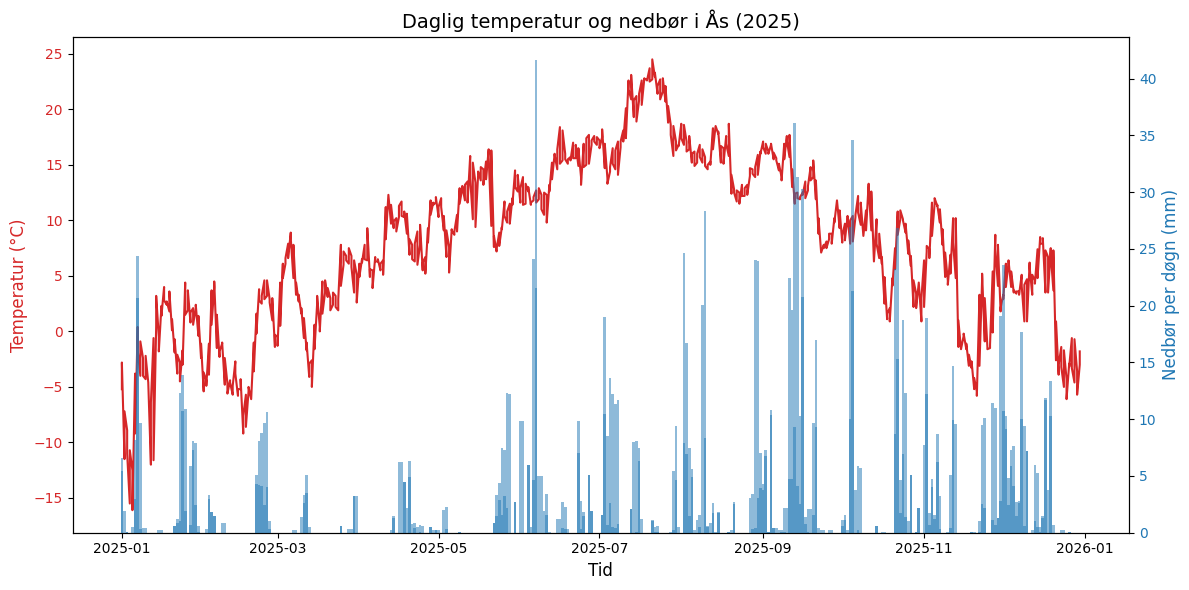

In [4]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

client_id = 'DIN_CLIENT_ID_HER'

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D),sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, parameters, auth=(client_id, ''))
json = r.json()

if r.status_code == 200:
    data = json['data']
    
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        for obs in item['observations']:
            rows.append({
                'referenceTime': ref_time,
                'elementId': obs['elementId'],
                'value': obs['value']
            })
    
    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])
    
    df_temp = df[df['elementId'] == 'mean(air_temperature P1D)']
    df_precip = df[df['elementId'] == 'sum(precipitation_amount P1D)']
    
    # Skriver ut mld i terminal først, slik at programmet ikke stopper. 
    print("Data for temperatur og nedbør hentet fra frost.met.no!")
    print(f"Antall temperaturmålinger: {len(df_temp)}")
    print(f"Antall nedbørsmålinger: {len(df_precip)}")

    # Viser plottet til slutt, for å få med både tall i terminal og plott
    fig, ax1 = plt.subplots(figsize=(12, 6))

    color_temp = 'tab:red'
    ax1.set_xlabel('Tid', fontsize=12)
    ax1.set_ylabel('Temperatur (°C)', color=color_temp, fontsize=12)
    ax1.plot(df_temp['referenceTime'], df_temp['value'], color=color_temp, linewidth=1.5, label='Temperatur')
    ax1.tick_params(axis='y', labelcolor=color_temp)

    ax2 = ax1.twinx()  
    color_precip = 'tab:blue'
    ax2.set_ylabel('Nedbør per døgn (mm)', color=color_precip, fontsize=12)
    ax2.bar(df_precip['referenceTime'], df_precip['value'], color=color_precip, alpha=0.5, width=1.0, label='Nedbør')
    ax2.tick_params(axis='y', labelcolor=color_precip)

    plt.title('Daglig temperatur og nedbør i Ås (2025)', fontsize=14)
    fig.tight_layout()
    
    plt.show()

else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

### Diskusjon av resultat (Task 2)
Ved å kombinere temperatur og døgnnedbør i samme diagram med to uavhengige y-akser (`twinx`), får vi en tydelig visuell sammenligning uten at måleenhetene (°C og mm) krasjer. Søylediagrammet viser at nedbøren er ujevnt fordelt utover året, med enkelte dager som skiller seg ut med spesielt høye nedbørsmengder.

## Task 3: Historical temperature data
Sammenligner daglig gjennomsnittstemperatur fra 1925 og 2025.


--- Oppsummeringstabell: 1925 vs 2025 ---
  År     Mean  Median   Min  Max
1925 5.310440    5.30 -20.7 24.3
2025 7.903571    8.35 -16.1 24.5


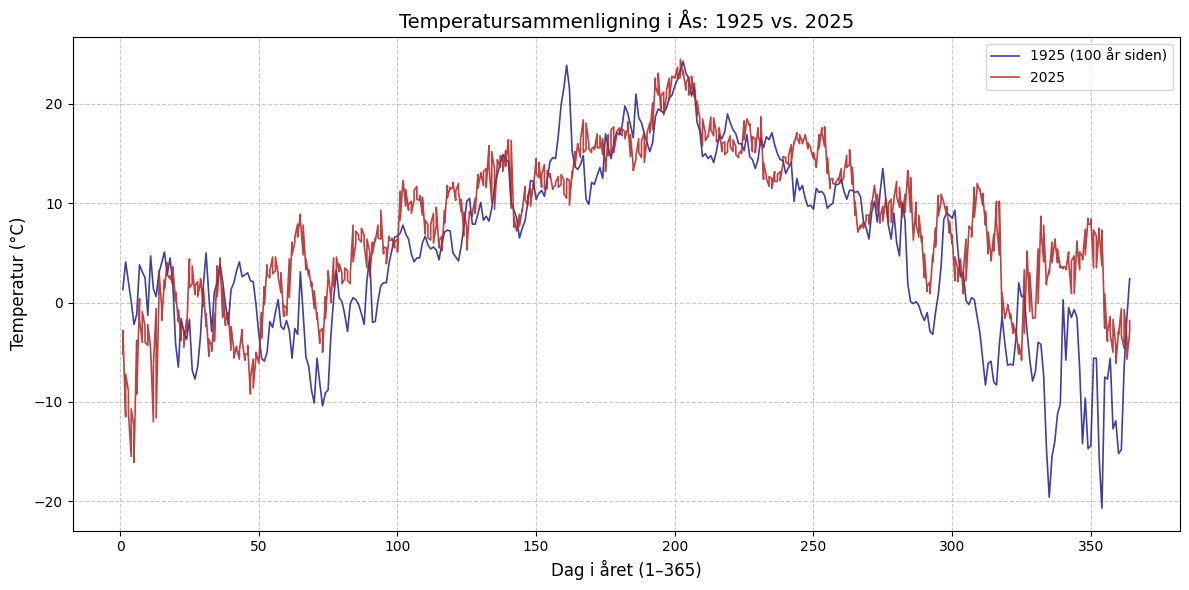

In [5]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

client_id = 'DIN_CLIENT_ID_HER'

endpoint = 'https://frost.met.no/observations/v0.jsonld'

# Hjelpefunksjon for å hente temperaturdata for et gitt år
def hent_temperatur_data(aar):
    parameters = {
        'sources': 'SN17850',
        'elements': 'mean(air_temperature P1D)',
        'referencetime': f'{aar}-01-01/{aar}-12-31',
    }
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    json_data = r.json()
    
    if r.status_code == 200:
        data = json_data['data']
        rows = []
        for item in data:
            ref_time = item['referenceTime']
            for obs in item['observations']:
                rows.append({
                    'referenceTime': ref_time,
                    'value': obs['value']
                })
        df = pd.DataFrame(rows)
        df['referenceTime'] = pd.to_datetime(df['referenceTime'])
        # Finn dag i året (1-365) slik at vi kan overlappe årene i plottet
        df['day_of_year'] = df['referenceTime'].dt.dayofyear
        return df
    else:
        print(f'Feil ved henting av data for {aar}: Status {r.status_code}')
        return None

# Henter data for både 1925 og 2025
df_1925 = hent_temperatur_data(1925)
df_2025 = hent_temperatur_data(2025)

if df_1925 is not None and df_2025 is not None:
   # Lager og skriver ut oppsummeringstabell FØRST ---
    summary_data = {
        'År': ['1925', '2025'],
        'Mean': [df_1925['value'].mean(), df_2025['value'].mean()],
        'Median': [df_1925['value'].median(), df_2025['value'].median()],
        'Min': [df_1925['value'].min(), df_2025['value'].min()],
        'Max': [df_1925['value'].max(), df_2025['value'].max()]
    }
    
    summary_table = pd.DataFrame(summary_data)
    print("\n--- Oppsummeringstabell: 1925 vs 2025 ---")
    print(summary_table.to_string(index=False))

    # Viser plottet til slutt, for å få med både tall i terminal og plott
    plt.figure(figsize=(12, 6))
    
    plt.plot(df_1925['day_of_year'], df_1925['value'], label='1925 (100 år siden)', color='navy', alpha=0.75, linewidth=1.2)
    plt.plot(df_2025['day_of_year'], df_2025['value'], label='2025', color='firebrick', alpha=0.85, linewidth=1.2)
    
    plt.title('Temperatursammenligning i Ås: 1925 vs. 2025', fontsize=14)
    plt.xlabel('Dag i året (1–365)', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    
    plt.show()

### Diskusjon av resultat (Task 3)
Sammenligningen av temperaturer fra 1925 og 2025 på en felles tidsakse (dag i året 1–365) illustrerer de historiske forskjellene over en 100-årsperiode. Oppsummeringstabellen og plottet viser endringer i både gjennomsnittstemperatur og ekstremverdier mellom de to årene.

## Task 4: Heatwaves
Lager en funksjon for å telle hetebølger (>= 5 sammenhengende dager med maks temp >= 27 °C) og lagrer sammendraget i en YAML-fil.

In [7]:
import requests
import pandas as pd
import yaml

client_id = 'DIN_CLIENT_ID_HER'

def count_heatwaves(station_id, year, client_id, yml_filename=None):
    """
    Teller antall hetebølger (>= 5 dager på rad med maks temp >= 27 °C)
    for en stasjon og et år, og lagrer sammendraget i en .yml-fil.
    """
    if yml_filename is None:
        yml_filename = f"heatwaves_{station_id}_{year}.yml"
        
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': station_id,
        'elements': 'max(air_temperature P1D)',
        'referencetime': f'{year}-01-01/{year}-12-31',
    }
    
    # Henter dataen fra Frost
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    json_data = r.json()
    
    if r.status_code != 200:
        print(f"Feil ved henting av data for {station_id} ({year}): Status {r.status_code}")
        print(json_data.get('error', {}).get('message', ''))
        return None
        
    data = json_data['data']
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        for obs in item['observations']:
            rows.append({
                'referenceTime': ref_time,
                'value': obs['value']
            })
            
    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])
    df = df.sort_values('referenceTime')
    
    # Algoritme for å telle hetebølger
    current_streak = 0
    heatwave_count = 0
    
    for temp in df['value']:
        if temp >= 27:
            current_streak += 1
        else:
            if current_streak >= 5:
                heatwave_count += 1
            current_streak = 0
            
    # Sjekker om en hetebølge varte helt ut årets siste dag
    if current_streak >= 5:
        heatwave_count += 1
        
    # Lagre sammendraget i en ordbok (dict)
    summary = {
        'station_id': station_id,
        'year': int(year),
        'element': 'max(air_temperature P1D)',
        'heatwave_threshold_temp_celsius': 27,
        'min_consecutive_days': 5,
        'number_of_heatwaves': heatwave_count
    }
    
    # Skriv til .yml-fil
    with open(yml_filename, 'w', encoding='utf-8') as f:
        yaml.dump(summary, f, default_flow_style=False, sort_keys=False)
        
    print(f"--- Resultat for stasjon {station_id} ({year}) ---")
    print(f"Antall hetebølger funnet: {heatwave_count}")
    print(f"Sammendrag lagret i filen: {yml_filename}\n")
    
    return heatwave_count


# Kjøring for Ås stasjon (SN17850) i 2025
count_heatwaves(station_id='SN17850', year=2025, client_id=CLIENT_ID)

# Kjører funksjonen for å finne hetebølger og opprette YAML-filen
count_heatwaves('SN17850', 2025, client_id)

# Leser og skriv ut innholdet i YAML-filen direkte i notatboken
with open("heatwaves_SN17850_2025.yml", "r", encoding="utf-8") as f:
    print("\n--- Innhold i YAML-filen ---")
    print(f.read())

--- Resultat for stasjon SN17850 (2025) ---
Antall hetebølger funnet: 1
Sammendrag lagret i filen: heatwaves_SN17850_2025.yml

--- Resultat for stasjon SN17850 (2025) ---
Antall hetebølger funnet: 1
Sammendrag lagret i filen: heatwaves_SN17850_2025.yml


--- Innhold i YAML-filen ---
station_id: SN17850
year: 2025
element: max(air_temperature P1D)
heatwave_threshold_temp_celsius: 27
min_consecutive_days: 5
number_of_heatwaves: 1



### Diskusjon av resultat (Task 4)
Funksjonen identifiserte **1 hetebølge** i Ås i 2025, basert på kriteriet om minst 5 sammenhengende dager med maksimumstemperatur på $\ge 27\text{ }^\circ\text{C}$. Sammendraget av analysen ble eksportert og lagret i YAML-filen `heatwaves_SN17850_2025.yml`.

## Task 5: Moving average temperature
Beregner et 7-dagers glidende gjennomsnitt for 2025 og plotter det som en linje over de daglige målingene.

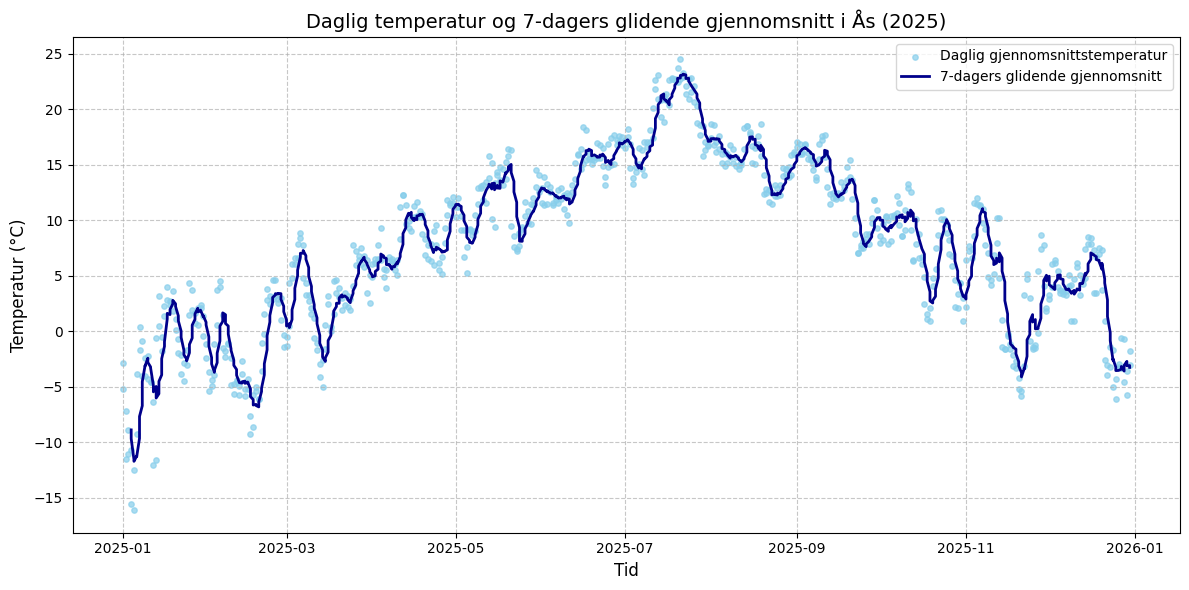

In [8]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

client_id = 'DIN_CLIENT_ID_HER'

# Funksjon som beregner 7-dagers glidende gjennomsnitt
def calculate_moving_average(series, window=7):
    """
    Beregner glidende gjennomsnitt for en Pandas Series over valgt vindulengde.
    """
    return series.rolling(window=window).mean()

# Hent gjennomsnittstemperatur for 2025 (fra Task 1)
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, parameters, auth=(client_id, ''))
json_data = r.json()

if r.status_code == 200:
    data = json_data['data']
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        for obs in item['observations']:
            rows.append({
                'referenceTime': ref_time,
                'value': obs['value']
            })
            
    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])
    df = df.sort_values('referenceTime')
    
    # Bruker funksjonen til å beregne 7-dagers glidende gjennomsnitt
    df['moving_avg'] = calculate_moving_average(df['value'], window=7)
    
    # Plotter daglig temperatur som punkter og glidende gjennomsnitt som linje
    plt.figure(figsize=(12, 6))
    
    # Daglig temperatur skrives ut som punkter (scatter)
    plt.scatter(
        df['referenceTime'], 
        df['value'], 
        color='skyblue', 
        alpha=0.7, 
        s=15, 
        label='Daglig gjennomsnittstemperatur'
    )
    
    # Glidende gjennomsnitt skrives ut som linje
    plt.plot(
        df['referenceTime'], 
        df['moving_avg'], 
        color='darkblue', 
        linewidth=2, 
        label='7-dagers glidende gjennomsnitt'
    )
    
    plt.title('Daglig temperatur og 7-dagers glidende gjennomsnitt i Ås (2025)', fontsize=14)
    plt.xlabel('Tid', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    
    plt.show()

else:
    print(f'Error! Returned status code {r.status_code}')

### Diskusjon av resultat (Task 5)
Det 7-dagers glidende gjennomsnittet demper de daglige temperatursvingningene og tydeliggjør den overordnede temperaturtrenden gjennom året. Kombinasjonen av punkter for de enkelte daglige målingene og en sammenhengende linje for det glidende snittet gir en lettlest visualisering av sesongutviklingen.
